# 02 — Exploration des rendements

Portefeuille de 100 000 €, un tiers par actif, rééquilibré chaque jour.

Les rendements sont **arithmétiques** : le rendement d'un portefeuille est exactement la moyenne
pondérée des rendements arithmétiques de ses actifs, ce qui n'est pas vrai des rendements logarithmiques
(ces derniers s'additionnent dans le temps, pas entre actifs).

In [1]:
import sys
from pathlib import Path

# Racine du projet (le notebook est dans notebooks/)
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(RACINE))
DATA, FIGURES = RACINE / "data", RACINE / "figures"
FIGURES.mkdir(exist_ok=True)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

from src.var_tools import rendements_portefeuille

MONTANT = 100_000
POIDS = pd.Series({"TTE.PA": 1/3, "SXR8.DE": 1/3, "EUNH.DE": 1/3})

prix = pd.read_csv(DATA / "prix.csv", index_col=0, parse_dates=True)
rend = prix.pct_change().dropna()
rend_pf = rendements_portefeuille(prix, POIDS)
pnl = MONTANT * rend_pf
print(len(rend_pf), "rendements journaliers")

2751 rendements journaliers


## Volatilité et diversification

In [3]:
vol = rend.std()
print((vol * 100).round(2).to_string(), "\n")
print(f"Moyenne des trois volatilités : {vol.mean():.2%}")
print(f"Volatilité du portefeuille    : {rend_pf.std():.2%}  → un jour typique ≈ {pnl.std():,.0f} €")

EUNH.DE    0.34
SXR8.DE    1.01
TTE.PA     1.67 

Moyenne des trois volatilités : 1.01%
Volatilité du portefeuille    : 0.77%  → un jour typique ≈ 772 €


## Les pires jours, et qui a perdu quoi

Le 9 mars 2020 correspond à la guerre des prix du pétrole entre l'Arabie saoudite et la Russie.
Les obligations n'ont pas protégé le portefeuille au pic de la crise.

In [4]:
print(pnl.nsmallest(5).round(0))
contrib = rend * POIDS * MONTANT
contrib.loc[["2020-03-09", "2020-03-12"]].round(0)

Date
2020-03-12   -7900.0
2020-03-09   -7781.0
2020-03-18   -6679.0
2020-05-04   -3484.0
2020-03-16   -3326.0
Name: rend_pf, dtype: float64


,EUNH.DE,SXR8.DE,TTE.PA
Date,,,
2020-03-09,-36.0,-2209.0,-5536.0
2020-03-12,-287.0,-2678.0,-4936.0


## Des queues épaisses

Sous une loi normale, le pire jour serait d'une rareté absurde. L'erreur de la loi normale est faible
à 2 σ et explose au-delà.

In [5]:
z_min = pnl.min() / pnl.std()
proba = norm.cdf(z_min)
print(f"Pire jour : {z_min:.1f} écarts-types, soit une fois tous les {1 / proba / 256:.0e} ans sous loi normale\n")

mu, sigma, n = rend_pf.mean(), rend_pf.std(), len(rend_pf)
queues = pd.DataFrame({
    "observés": [(rend_pf < mu - k * sigma).sum() for k in [2, 3, 4, 5]],
    "attendus (loi normale)": [round(n * norm.cdf(-k), 2) for k in [2, 3, 4, 5]],
}, index=[f"sous -{k}σ" for k in [2, 3, 4, 5]])
print(queues, "\n")
print("Kurtosis en excès :", round(rend_pf.kurt(), 1), "(0 pour une loi normale)")

Pire jour : -10.2 écarts-types, soit une fois tous les 6e+21 ans sous loi normale

          observés  attendus (loi normale)
sous -2σ        71                   62.59
sous -3σ        26                    3.71
sous -4σ        10                    0.09
sous -5σ         3                    0.00 

Kurtosis en excès : 16.1 (0 pour une loi normale)


## Une volatilité qui vient par vagues

Date
2016    0.83
2017    0.39
2018    0.65
2019    0.56
2020    1.54
2021    0.63
2022    0.88
2023    0.60
2024    0.51
2025    0.70
2026    0.48

Rapport année la plus agitée / la plus calme : 3.9


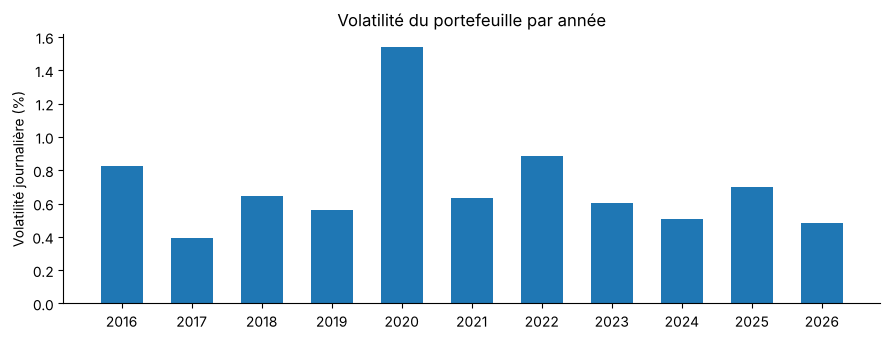

In [6]:
vol_an = rend_pf.groupby(rend_pf.index.year).std() * 100
print(vol_an.round(2).to_string())
print(f"\nRapport année la plus agitée / la plus calme : {vol_an.max() / vol_an.min():.1f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(vol_an.index.astype(str), vol_an.values, color="C0", width=0.6)
ax.set_ylabel("Volatilité journalière (%)")
ax.set_title("Volatilité du portefeuille par année")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "volatilite_annuelle.png", dpi=150)
plt.show()